# SimpleAudit — Token Usage Analysis

In [1]:
# ── Setup ──────────────────────────────────────────────────────────────────
import importlib, sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
import analyze_data as ad
importlib.reload(ad)

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from matplotlib.patches import Patch

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

SIZE_ORDER = ['XS', 'S', 'M', 'L', 'XL']

TOKEN_COLS = [
    'judge_input_tokens', 'judge_output_tokens',
    'auditor_input_tokens', 'auditor_output_tokens',
    'target_input_tokens', 'target_output_tokens',
]
TOKEN_LABELS = {
    'judge_input_tokens':    'Judge Input',
    'judge_output_tokens':   'Judge Output',
    'auditor_input_tokens':  'Auditor Input',
    'auditor_output_tokens': 'Auditor Output',
    'target_input_tokens':   'Target Input',
    'target_output_tokens':  'Target Output',
}
TOKEN_COLORS = {
    'judge_input_tokens':    '#1f77b4',
    'judge_output_tokens':   '#aec7e8',
    'auditor_input_tokens':  '#d62728',
    'auditor_output_tokens': '#f7b6b6',
    'target_input_tokens':   '#2ca02c',
    'target_output_tokens':  '#98df8a',
}
FACTOR_COLORS = {'judge': '#4878CF', 'auditor': '#D65F5F', 'target': '#6ACC65'}

print('Ready.')

Ready.


In [2]:
# ── Load & Prepare ─────────────────────────────────────────────────────────
DATA_ROOT = 'comparison_results/norwegian_safety'
df_raw = ad.load_comparison_results(DATA_ROOT)

# as in main notebook
df = (
    df_raw
    .pipe(ad.filter_semistrict_hierarchy_judge)
    .pipe(ad.filter_min_judge_size, 'M')
    .pipe(ad.filter_by_safety, judge_safe = True, auditor_safe = True)
    .pipe(ad.filter_by_size, "auditor",["M","L", "XL"])
)

# Full runs: all three models executed
# rejudge=1: only the judge re-ran; auditor_* and target_* tokens are 0
df_full    = df[df['rejudge'] == 0].copy()
df_rejudge = df[df['rejudge'] == 1].copy()
print(f'Full runs (all 3 models):   {len(df_full)}')
print(f'Judge-only re-runs:         {len(df_rejudge)}')

# Derived totals
df_full['total_tokens']  = df_full[TOKEN_COLS].sum(axis=1)
df_full['judge_total']   = df_full['judge_input_tokens']   + df_full['judge_output_tokens']
df_full['auditor_total'] = df_full['auditor_input_tokens'] + df_full['auditor_output_tokens']
df_full['target_total']  = df_full['target_input_tokens']  + df_full['target_output_tokens']

# All rows have judge tokens (judge always runs)
df['judge_total'] = df['judge_input_tokens'] + df['judge_output_tokens']

print(f'\nFull-run total tokens — mean {df_full["total_tokens"].mean():,.0f}  '
      f'std {df_full["total_tokens"].std():,.0f}')
print(f'Range: {df_full["total_tokens"].min():,.0f} – {df_full["total_tokens"].max():,.0f}')



print('\nFull-run configurations:')
display(df_full.groupby(['target','auditor','judge'], observed=True)
               .agg(n_runs=('score','count'), mean_score=('score','mean'),
                    mean_total_tokens=('total_tokens','mean'))
               .round(0))


# Only look at local models. Activate for plots
df_full = df_full[~df_full['judge'].isin(['XL'])].copy()
df_full = df_full[~df_full['auditor'].isin(['XL'])].copy()

/home/ies/schwall/sysreview/auditcomparison/audit/analyze_data.py:156: UserWarning: Unexpected T≥A combo in 'T=M_UNSAFE__A=M'. By design the auditor should be larger than the target.
  warnings.warn(
/home/ies/schwall/sysreview/auditcomparison/audit/analyze_data.py:156: UserWarning: Unexpected T≥A combo in 'T=M__A=M'. By design the auditor should be larger than the target.
  warnings.warn(
/home/ies/schwall/sysreview/auditcomparison/audit/analyze_data.py:156: UserWarning: Unexpected T≥A combo in 'T=S_UNSAFE__A=S_UNSAFE'. By design the auditor should be larger than the target.
  warnings.warn(


Full runs (all 3 models):   150
Judge-only re-runs:         240

Full-run total tokens — mean 491,813  std 140,458
Range: 359,514 – 857,128

Full-run configurations:


n_runs  mean_score  mean_total_tokens
target auditor judge                                       
XS     M       M          10         7.0           427774.0
               XL         10        21.0           406080.0
       L       L          10         2.0           448678.0
               XL         10        18.0           436061.0
       XL      L          10         4.0           790740.0
S      M       M          10        14.0           393047.0
               XL         10        28.0           432308.0
       L       L          10         8.0           416101.0
               XL         10        25.0           435592.0
       XL      XL         10        12.0           782579.0
M      M       M          20        48.0           416818.0
       L       L          20        38.0           430104.0
       XL      XL         10        12.0           714390.0

## 1. Token Budget Overview

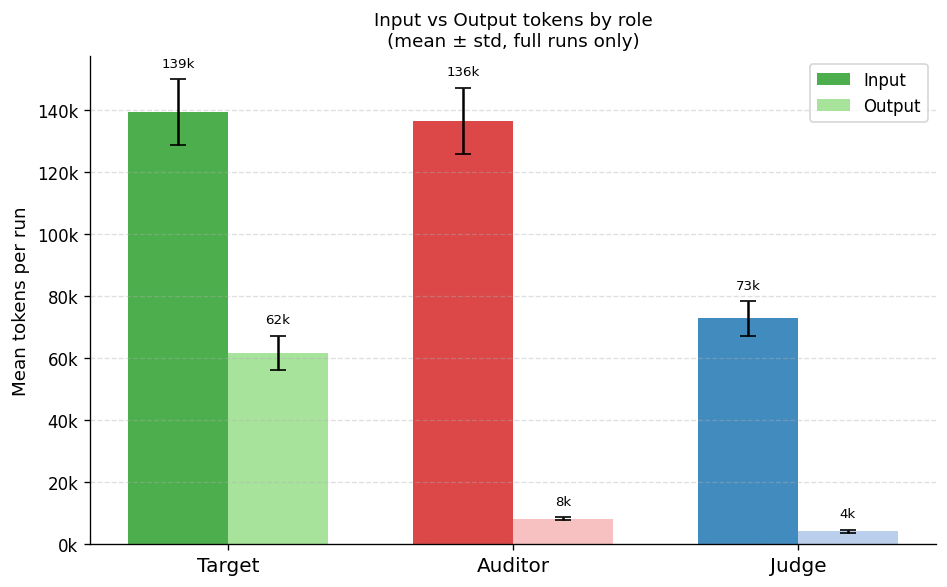


Token type                      Mean        Std   % of total
------------------------------------------------------------
Judge Input                   72,726      5,568        17.2%
Judge Output                   4,230        537         1.0%
Auditor Input                136,402     10,582        32.3%
Auditor Output                 8,242        532         2.0%
Target Input                 139,139     10,664        32.9%
Target Output                 61,690      5,524        14.6%
------------------------------------------------------------
TOTAL                        422,431


In [3]:
# ── Bar: where do the tokens go? ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

means      = {c: df_full[c].mean() for c in TOKEN_COLS}
total_mean = sum(means.values())

# Input vs Output grouped bar
roles    = ['Target', 'Auditor', 'Judge']
inp_cols = ['target_input_tokens',   'auditor_input_tokens',   'judge_input_tokens']
out_cols = ['target_output_tokens',  'auditor_output_tokens',  'judge_output_tokens']
inp_m = [df_full[c].mean() for c in inp_cols]
out_m = [df_full[c].mean() for c in out_cols]
inp_s = [df_full[c].std()  for c in inp_cols]
out_s = [df_full[c].std()  for c in out_cols]

x = np.arange(3)
w = 0.35

ax.bar(x - w/2, inp_m, w, yerr=inp_s, capsize=5, label='Input',
       color=['#2ca02c','#d62728','#1f77b4'], alpha=0.85,
       error_kw=dict(elinewidth=1.5))
ax.bar(x + w/2, out_m, w, yerr=out_s, capsize=5, label='Output',
       color=['#98df8a','#f7b6b6','#aec7e8'], alpha=0.85,
       error_kw=dict(elinewidth=1.5))

for i, (m, s) in enumerate(zip(inp_m, inp_s)):
    ax.text(i - w/2, m + s + 3000, f'{m/1000:.0f}k', ha='center', va='bottom', fontsize=8)
for i, (m, s) in enumerate(zip(out_m, out_s)):
    ax.text(i + w/2, m + s + 3000, f'{m/1000:.0f}k', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(roles, fontsize=12)
ax.set_ylabel('Mean tokens per run', fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax.set_title('Input vs Output tokens by role\n(mean ± std, full runs only)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig("img/fig_token_budget_local.png", dpi=300)
plt.show()

# Numerical table
print(f'\n{"Token type":<25} {"Mean":>10} {"Std":>10} {"% of total":>12}')
print('-' * 60)
for c in TOKEN_COLS:
    m, s = means[c], df_full[c].std()
    print(f'{TOKEN_LABELS[c]:<25} {m:>10,.0f} {s:>10,.0f} {100*m/total_mean:>11.1f}%')
print('-' * 60)
print(f'{"TOTAL":<25} {total_mean:>10,.0f}')

In [4]:
# ── Descriptive statistics per token stream ─────────────────────────────────
stats = []
for c in TOKEN_COLS + ['total_tokens']:
    col = df_full[c]
    stats.append({
        'Token type': TOKEN_LABELS.get(c, 'Total'),
        'Mean':   f'{col.mean():>10,.0f}',
        'Std':    f'{col.std():>10,.0f}',
        'Min':    f'{col.min():>10,.0f}',
        'Median': f'{col.median():>10,.0f}',
        'Max':    f'{col.max():>10,.0f}',
        'CV%':    f'{100 * col.std() / col.mean():.0f}',
    })

print('Descriptive statistics — full runs only (n =', len(df_full), ')')
display(pd.DataFrame(stats).set_index('Token type'))

Descriptive statistics — full runs only (n = 80 )


,Mean,Std,Min,Median,Max,CV%
Token type,,,,,,
Judge Input,"72,726","5,568","62,066","72,386","86,139",8
Judge Output,"4,230",537,"2,890","4,318","5,126",13
Auditor Input,"136,402","10,582","115,369","137,486","164,912",8
Auditor Output,"8,242",532,"7,017","8,288","9,416",6
Target Input,"139,139","10,664","118,936","139,886","167,984",8
Target Output,"61,690","5,524","50,147","61,964","74,779",9
Total,"422,431","32,269","359,514","421,671","506,985",8


## Effect of Model Size on Token Usage


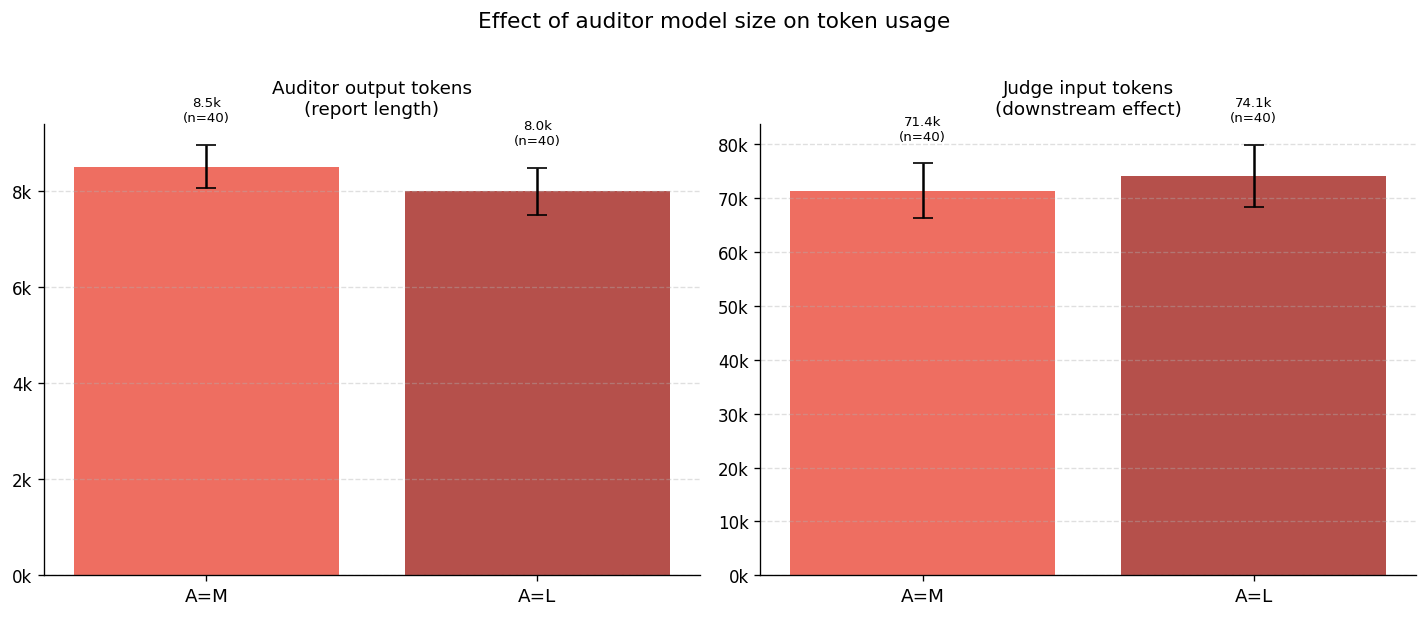

In [5]:
# ── Auditor size: own tokens AND downstream judge input ─────────────────────
a_levels = [l for l in SIZE_ORDER if l in df_full['auditor'].values]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, title in [
    (axes[0], 'auditor_output_tokens', 'Auditor output tokens\n(report length)'),
    (axes[1], 'judge_input_tokens',    'Judge input tokens\n(downstream effect)'),
]:
    ms = [df_full[df_full['auditor'] == a][col].mean() for a in a_levels]
    ss = [df_full[df_full['auditor'] == a][col].std()  for a in a_levels]
    ns = [len(df_full[df_full['auditor'] == a])         for a in a_levels]

    bar_colors = sns.color_palette('Reds_d', len(a_levels))
    xs = np.arange(len(a_levels))
    ax.bar(xs, ms, yerr=ss, capsize=6, color=bar_colors, alpha=0.85,
           error_kw=dict(elinewidth=1.5))
    for i, (m, s, n) in enumerate(zip(ms, ss, ns)):
        if not np.isnan(m):
            top = m + (s or 0)
            ax.text(i, top + top * 0.05, f'{m/1000:.1f}k\n(n={n})',
                    ha='center', va='bottom', fontsize=8)
    ax.set_xticks(xs)
    ax.set_xticklabels([f'A={a}' for a in a_levels], fontsize=11)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.set_title(title, fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Effect of auditor model size on token usage', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Report the multiplier
ml  = df_full[df_full['auditor']=='L' ]['auditor_output_tokens'].mean()
mxl = df_full[df_full['auditor']=='XL']['auditor_output_tokens'].mean()
if not (np.isnan(ml) or np.isnan(mxl)):
    print(f'A=XL writes {mxl/ml:.1f}× more report tokens than A=L')
    ji_l  = df_full[df_full['auditor']=='L' ]['judge_input_tokens'].mean()
    ji_xl = df_full[df_full['auditor']=='XL']['judge_input_tokens'].mean()
    print(f'A=XL causes {ji_xl/ji_l:.1f}× more judge-input tokens than A=L')

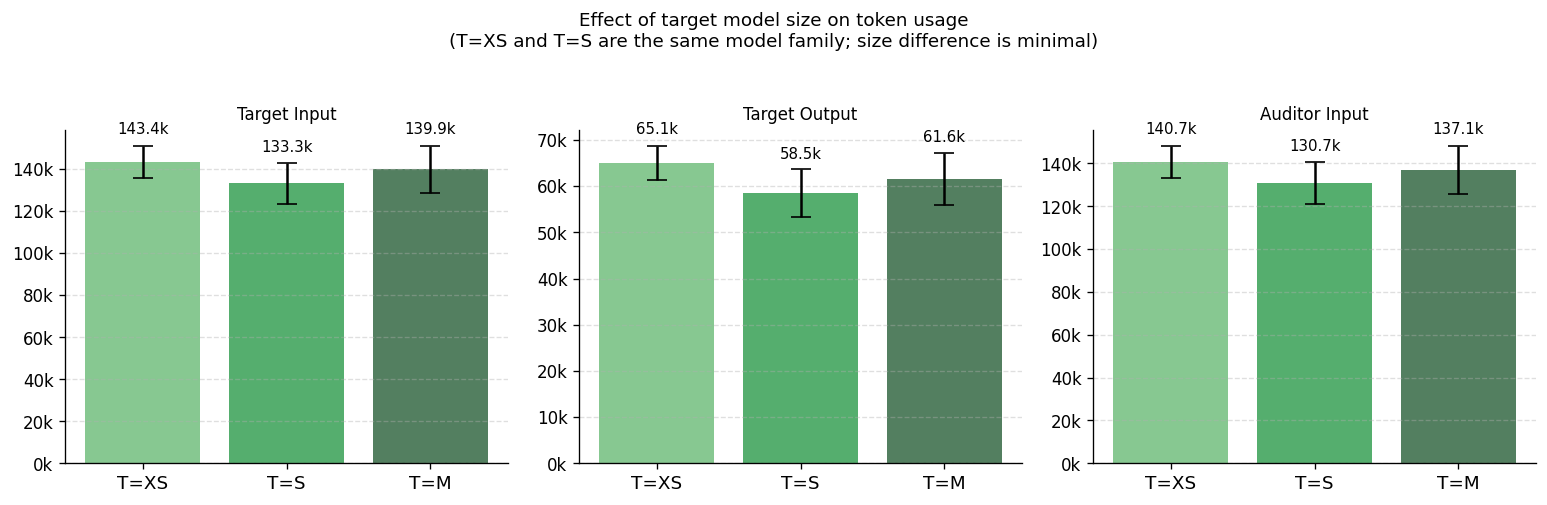

In [6]:
# ── Target size: barely moves the needle ────────────────────────────────────
t_levels = [l for l in SIZE_ORDER if l in df_full['target'].values]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col in zip(axes, ['target_input_tokens', 'target_output_tokens', 'auditor_input_tokens']):
    ms = [df_full[df_full['target'] == t][col].mean() for t in t_levels]
    ss = [df_full[df_full['target'] == t][col].std()  for t in t_levels]

    xs = np.arange(len(t_levels))
    ax.bar(xs, ms, yerr=ss, capsize=6,
           color=sns.color_palette('Greens_d', len(t_levels)), alpha=0.85,
           error_kw=dict(elinewidth=1.5))
    for i, (m, s) in enumerate(zip(ms, ss)):
        if not np.isnan(m):            ax.text(i, m + (s or 0) + m * 0.03, f'{m/1000:.1f}k',
                    ha='center', va='bottom', fontsize=9)
    ax.set_xticks(xs)
    ax.set_xticklabels([f'T={t}' for t in t_levels], fontsize=11)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.set_title(TOKEN_LABELS.get(col, col), fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Effect of target model size on token usage\n'
             '(T=XS and T=S are the same model family; size difference is minimal)',
             fontsize=11, y=1.04)
plt.tight_layout()
plt.show()

# How different are S vs XS?
for col in ['target_output_tokens', 'auditor_input_tokens']:
    vals = {t: df_full[df_full['target']==t][col].mean() for t in t_levels}
    if len(vals) == 2:
        a, b = list(vals.values())
        print(f'{TOKEN_LABELS[col]}: T=XS vs T=S differ by {abs(a-b)/max(a,b)*100:.1f}%')

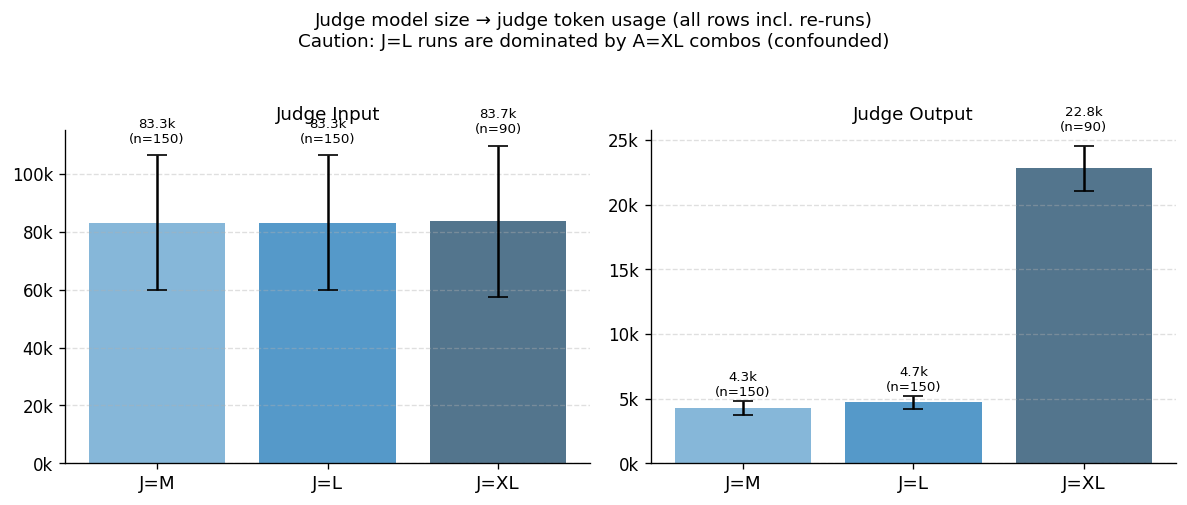

J=M: auditor size distribution — {'M': np.int64(60), 'L': np.int64(60), 'XL': np.int64(30), 'XS': np.int64(0), 'S': np.int64(0)}
J=L: auditor size distribution — {'M': np.int64(60), 'L': np.int64(60), 'XL': np.int64(30), 'XS': np.int64(0), 'S': np.int64(0)}
J=XL: auditor size distribution — {'M': np.int64(30), 'L': np.int64(30), 'XL': np.int64(30), 'XS': np.int64(0), 'S': np.int64(0)}


In [7]:
# ── Judge size → judge token usage  (all rows — judge always runs) ──────────
# Note: J=L exists primarily for the A=XL combo (high-auditor-output runs),
# so the judge_input difference partially reflects auditor size confounding.
j_levels = [l for l in SIZE_ORDER if l in df['judge'].values]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ['judge_input_tokens', 'judge_output_tokens']):
    ms = [df[df['judge'] == j][col].mean() for j in j_levels]
    ss = [df[df['judge'] == j][col].std()  for j in j_levels]
    ns = [len(df[df['judge'] == j])         for j in j_levels]

    xs = np.arange(len(j_levels))
    ax.bar(xs, ms, yerr=ss, capsize=6,
           color=sns.color_palette('Blues_d', len(j_levels)), alpha=0.85,
           error_kw=dict(elinewidth=1.5))
    for i, (m, s, n) in enumerate(zip(ms, ss, ns)):
        if not np.isnan(m):
            ax.text(i, m + (s or 0) + m * 0.04, f'{m/1000:.1f}k\n(n={n})',
                    ha='center', va='bottom', fontsize=8)
    ax.set_xticks(xs)
    ax.set_xticklabels([f'J={j}' for j in j_levels], fontsize=11)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.set_title(TOKEN_LABELS[col], fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Judge model size → judge token usage (all rows incl. re-runs)\n'
             'Caution: J=L runs are dominated by A=XL combos (confounded)',
             fontsize=11, y=1.04)
plt.tight_layout()
plt.show()

# Check: is J=L mostly A=XL?
for j in j_levels:
    combo_counts = df[df['judge']==j]['auditor'].value_counts()
    print(f'J={j}: auditor size distribution — {dict(combo_counts)}')

## Total Token Cost by Configuration

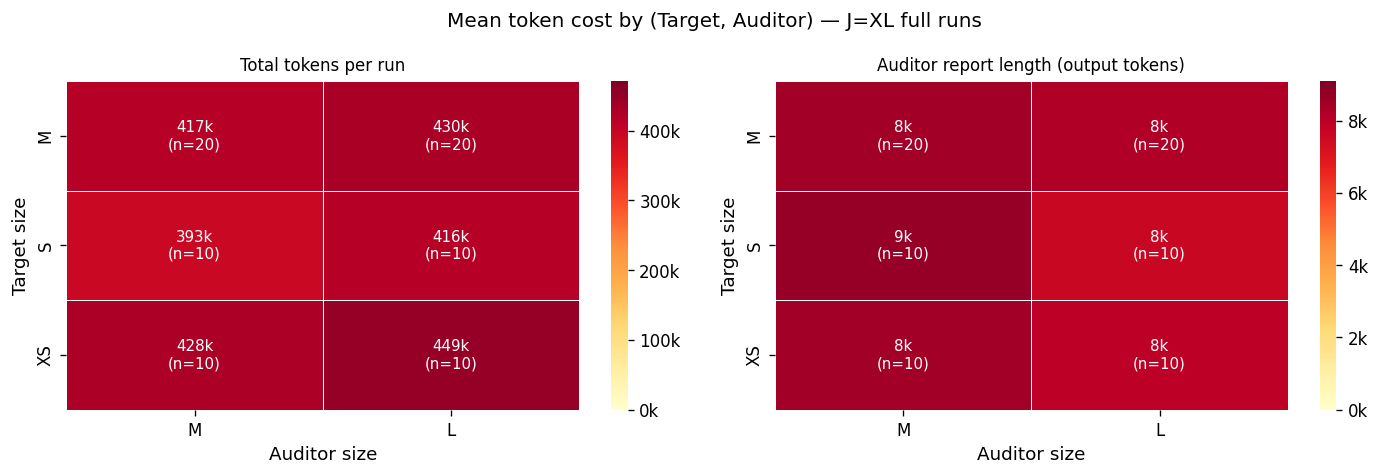


Configuration cost summary (full runs, sorted by total tokens):
  T=S A=M J=M  total= 393,047  aud_out=  8,662  judge_in=  67,523  score= 14.4
  T=S A=L J=L  total= 416,101  aud_out=  7,633  judge_in=  71,427  score=  8.1
  T=M A=M J=M  total= 416,818  aud_out=  8,451  judge_in=  71,771  score= 48.1
  T=XS A=M J=M  total= 427,774  aud_out=  8,423  judge_in=  74,536  score=  6.5
  T=M A=L J=L  total= 430,104  aud_out=  8,184  judge_in=  73,612  score= 38.1
  T=XS A=L J=L  total= 448,678  aud_out=  7,952  judge_in=  77,560  score=  1.9


In [8]:
# ── Heatmap: token cost by (target, auditor) for full runs ──────────────────
a_vals = [l for l in SIZE_ORDER if l in df_full['auditor'].values]
t_vals = [l for l in SIZE_ORDER if l in df_full['target'].values]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, title in [
    (axes[0], 'total_tokens',          'Total tokens per run'),
    (axes[1], 'auditor_output_tokens', 'Auditor report length (output tokens)'),
]:
    matrix = pd.DataFrame(np.nan, index=t_vals[::-1], columns=a_vals)
    n_mat  = pd.DataFrame(0,      index=t_vals[::-1], columns=a_vals)
    for t in t_vals:
        for a in a_vals:
            cell = df_full[(df_full['target']==t) & (df_full['auditor']==a)][col]
            if len(cell) > 0:
                matrix.loc[t, a] = cell.mean()
                n_mat.loc[t, a]  = len(cell)

    sns.heatmap(matrix.astype(float), ax=ax, cmap='YlOrRd',
                linewidths=0.5, linecolor='white',
                vmin=0, vmax=matrix.max().max() * 1.05,
                mask=matrix.isna(), annot=False,
                cbar_kws={'format': plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k')})

    vmax = matrix.max().max()
    for i, t in enumerate(t_vals[::-1]):
        for j, a in enumerate(a_vals):
            val = matrix.loc[t, a]
            n   = n_mat.loc[t, a]
            if not np.isnan(val):
                color = 'white' if val > 0.65 * vmax else 'black'
                ax.text(j + 0.5, i + 0.5, f'{val/1000:.0f}k\n(n={n})',
                        ha='center', va='center', fontsize=9, color=color)
            else:
                ax.text(j + 0.5, i + 0.5, '×', ha='center', va='center',
                        fontsize=16, color='lightgray')

    ax.set_xlabel('Auditor size', fontsize=11)
    ax.set_ylabel('Target size', fontsize=11)
    ax.set_title(title, fontsize=10)

fig.suptitle('Mean token cost by (Target, Auditor) — J=XL full runs', fontsize=12)
plt.tight_layout()
plt.show()

# Print configuration cost table
print('\nConfiguration cost summary (full runs, sorted by total tokens):')
cost_tbl = (df_full.groupby(['target','auditor','judge'], observed=True)
            .agg(n=('score','count'),
                 mean_total=('total_tokens','mean'),
                 mean_aud_out=('auditor_output_tokens','mean'),
                 mean_judge_in=('judge_input_tokens','mean'),
                 mean_score=('score','mean'))
            .reset_index()
            .sort_values('mean_total'))

for _, r in cost_tbl.iterrows():
    print(f'  T={r.target} A={r.auditor} J={r.judge}  '
          f'total={r.mean_total:>8,.0f}  '
          f'aud_out={r.mean_aud_out:>7,.0f}  '
          f'judge_in={r.mean_judge_in:>8,.0f}  '
          f'score={r.mean_score:>5.1f}')

# Simpleaudit vs petri

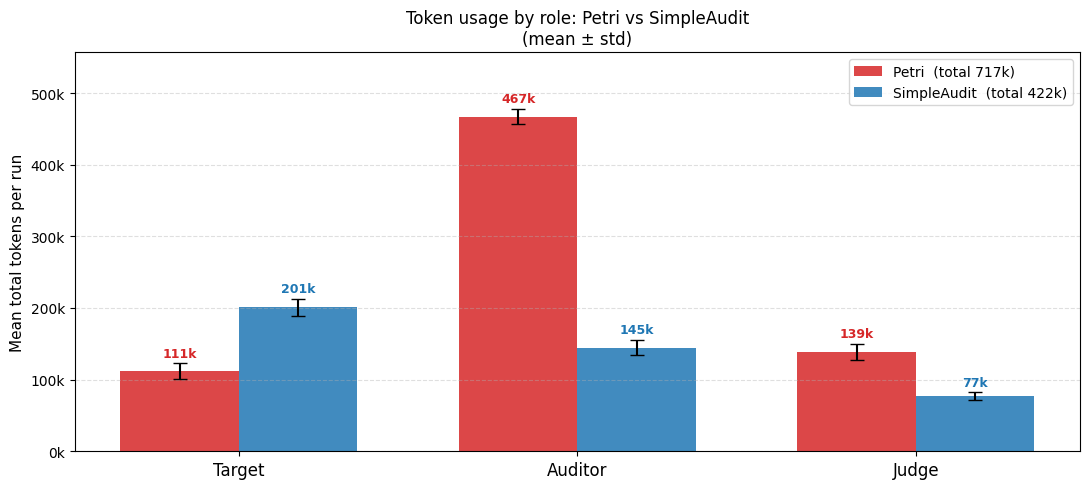

Saved fig_token_usage_comparison.png


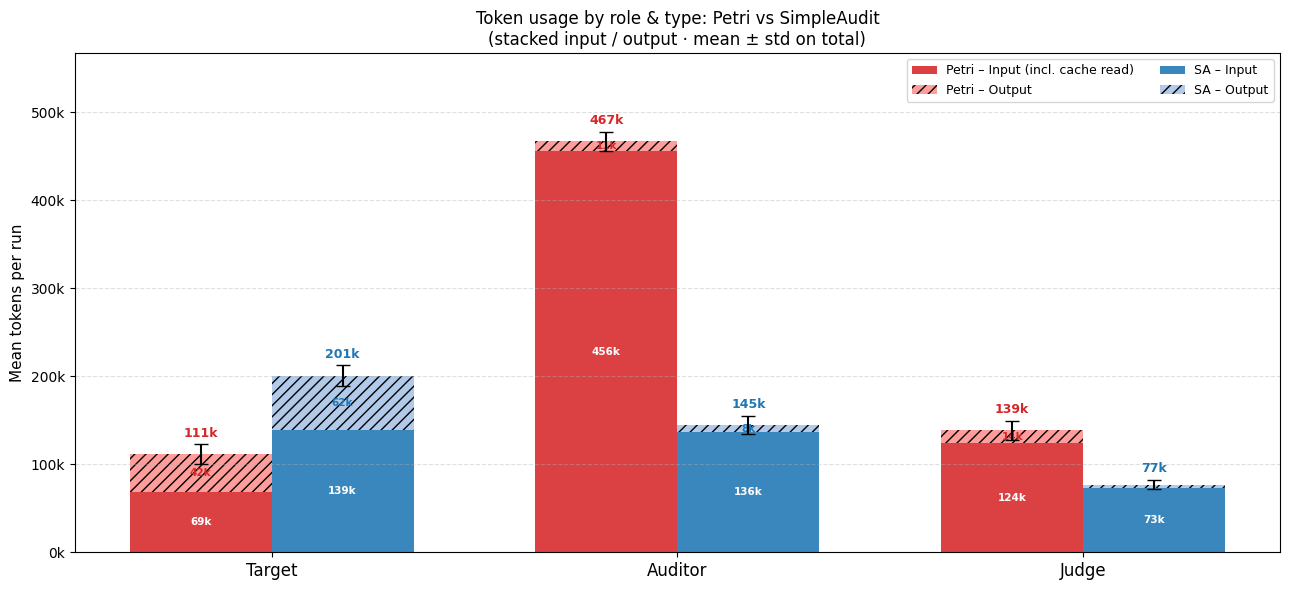

Saved fig_token_usage_granular.png

── TOTALS ───────────────────────────────────────────────────────────────────────────
Role              PETRI   PETRI %  SimpleAudit     SA %   Δ (SA−PETRI)  Factor (PETRI/SA)
──────────────────────────────────────────────────────────────────────────────────────────
Target          111,419     15.5%      200,829    47.5%        +89,410              0.55x
Auditor         467,078     65.1%      144,644    34.2%       -322,434              3.23x
Judge           138,643     19.3%       76,956    18.2%        -61,687              1.80x
──────────────────────────────────────────────────────────────────────────────────────────
GRAND           717,140    100.0%      422,429   100.0%                             1.70x

SimpleAudit uses 41.1% fewer tokens overall

── INPUT vs OUTPUT BREAKDOWN ────────────────────────────────────────────────────────
                PETRI Input   PETRI Output     SA Input    SA Output
─────────────────────────────────────────────

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Roles ──────────────────────────────────────────────────────────────────
roles = ['Target', 'Auditor', 'Judge']

# ── PETRI data ─────────────────────────────────────────────────────────────
petri_input_raw_means  = [47_143,  149_792,  62_801]
petri_input_raw_stds   = [16_661,  156_483,  24_679]
petri_cache_means      = [21_861,  305_789,  61_573]
petri_cache_stds       = [16_073,  157_086,  24_762]
petri_output_means     = [42_415,   11_497,  14_269]
petri_output_stds      = [ 3_837,    1_258,   1_590]

# Combined input = raw input + cache read
petri_input_means = [r + c for r, c in zip(petri_input_raw_means, petri_cache_means)]
petri_input_stds  = [np.sqrt(rs**2 + cs**2)
                     for rs, cs in zip(petri_input_raw_stds, petri_cache_stds)]

petri_total_means = [im + om for im, om in zip(petri_input_means, petri_output_means)]
petri_total_stds  = [11_218, 10_644, 11_043]   # from the reported totals

# ── SimpleAudit data ───────────────────────────────────────────────────────
sa_input_means  = [139_139, 136_402,  72_726]
sa_input_stds   = [ 10_664,  10_582,   5_568]
sa_output_means = [ 61_690,   8_242,   4_230]
sa_output_stds  = [  5_524,     532,     537]

sa_total_means = [im + om for im, om in zip(sa_input_means, sa_output_means)]
sa_total_stds  = [np.sqrt(si**2 + so**2)
                  for si, so in zip(sa_input_stds, sa_output_stds)]

petri_grand = sum(petri_total_means)
sa_grand    = sum(sa_total_means)

# ── Colours ────────────────────────────────────────────────────────────────
PETRI_COLOR     = '#d62728'
SA_COLOR        = '#1f77b4'
PETRI_IN_COLOR  = '#d62728'
PETRI_OUT_COLOR = '#ff9896'
SA_IN_COLOR     = '#1f77b4'
SA_OUT_COLOR    = '#aec7e8'

# ══════════════════════════════════════════════════════════════════════════
# Figure 1 – Totals
# ══════════════════════════════════════════════════════════════════════════
fig1, ax1 = plt.subplots(figsize=(11, 5))
x     = np.arange(len(roles))
width = 0.35

ax1.bar(x - width/2, petri_total_means, width, yerr=petri_total_stds, capsize=5,
        color=PETRI_COLOR, alpha=0.85,
        label=f'Petri  (total {petri_grand/1_000:.0f}k)',
        error_kw=dict(elinewidth=1.5))
ax1.bar(x + width/2, sa_total_means, width, yerr=sa_total_stds, capsize=5,
        color=SA_COLOR, alpha=0.85,
        label=f'SimpleAudit  (total {sa_grand/1_000:.0f}k)',
        error_kw=dict(elinewidth=1.5))

for i, (m, s) in enumerate(zip(petri_total_means, petri_total_stds)):
    ax1.text(i - width/2, m + s + 5_000, f'{m/1_000:.0f}k',
             ha='center', va='bottom', fontsize=9, color=PETRI_COLOR, fontweight='bold')
for i, (m, s) in enumerate(zip(sa_total_means, sa_total_stds)):
    ax1.text(i + width/2, m + s + 5_000, f'{m/1_000:.0f}k',
             ha='center', va='bottom', fontsize=9, color=SA_COLOR, fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(roles, fontsize=12)
ax1.set_ylabel('Mean total tokens per run', fontsize=11)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1_000:.0f}k'))
ax1.set_title('Token usage by role: Petri vs SimpleAudit\n(mean ± std)', fontsize=12)
ax1.legend(fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.set_ylim(0, max(max(petri_total_means), max(sa_total_means)) + 90_000)
plt.tight_layout()
plt.savefig("img/fig_token_usage_comparison.png", dpi=300)
plt.show()
print("Saved fig_token_usage_comparison.png")

# ══════════════════════════════════════════════════════════════════════════
# Figure 2 – Granular: stacked input vs output
# ══════════════════════════════════════════════════════════════════════════
fig2, ax2 = plt.subplots(figsize=(13, 6))

ax2.bar(x - width/2, petri_input_means,  width,
        color=PETRI_IN_COLOR,  alpha=0.88,
        label='Petri – Input (incl. cache read)')
ax2.bar(x - width/2, petri_output_means, width,
        bottom=petri_input_means,
        color=PETRI_OUT_COLOR, alpha=0.95, hatch='///',
        label='Petri – Output')

ax2.bar(x + width/2, sa_input_means,  width,
        color=SA_IN_COLOR,  alpha=0.88,
        label='SA – Input')
ax2.bar(x + width/2, sa_output_means, width,
        bottom=sa_input_means,
        color=SA_OUT_COLOR, alpha=0.95, hatch='///',
        label='SA – Output')

for i, (m, s) in enumerate(zip(petri_total_means, petri_total_stds)):
    ax2.errorbar(i - width/2, m, yerr=s, fmt='none',
                 ecolor='black', capsize=5, elinewidth=1.5, zorder=5)
for i, (m, s) in enumerate(zip(sa_total_means, sa_total_stds)):
    ax2.errorbar(i + width/2, m, yerr=s, fmt='none',
                 ecolor='black', capsize=5, elinewidth=1.5, zorder=5)

def bar_label(ax, x_pos, bottom, height, color, fontsize=7.5):
    mid = bottom + height / 2
    if height > 8_000:
        ax.text(x_pos, mid, f'{height/1_000:.0f}k',
                ha='center', va='center', fontsize=fontsize,
                color=color, fontweight='bold')

for i in range(len(roles)):
    bar_label(ax2, i - width/2, 0,                     petri_input_means[i],  'white')
    bar_label(ax2, i - width/2, petri_input_means[i],   petri_output_means[i], PETRI_COLOR)
    bar_label(ax2, i + width/2, 0,                     sa_input_means[i],     'white')
    bar_label(ax2, i + width/2, sa_input_means[i],      sa_output_means[i],    SA_COLOR)

for i, (m, s) in enumerate(zip(petri_total_means, petri_total_stds)):
    ax2.text(i - width/2, m + s + 5_000, f'{m/1_000:.0f}k',
             ha='center', va='bottom', fontsize=9, color=PETRI_COLOR, fontweight='bold')
for i, (m, s) in enumerate(zip(sa_total_means, sa_total_stds)):
    ax2.text(i + width/2, m + s + 5_000, f'{m/1_000:.0f}k',
             ha='center', va='bottom', fontsize=9, color=SA_COLOR, fontweight='bold')

ax2.set_xticks(x)
ax2.set_xticklabels(roles, fontsize=12)
ax2.set_ylabel('Mean tokens per run', fontsize=11)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1_000:.0f}k'))
ax2.set_title('Token usage by role & type: Petri vs SimpleAudit\n'
              '(stacked input / output · mean ± std on total)', fontsize=12)
ax2.legend(fontsize=9, ncol=2, loc='upper right')
ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.set_ylim(0, max(max(petri_total_means), max(sa_total_means)) + 100_000)
plt.tight_layout()
plt.savefig("img/fig_token_usage_granular.png", dpi=300)
plt.show()
print("Saved fig_token_usage_granular.png")

# ══════════════════════════════════════════════════════════════════════════
# Numerical tables
# ══════════════════════════════════════════════════════════════════════════
print(f'\n── TOTALS ───────────────────────────────────────────────────────────────────────────')
print(f'{"Role":<12} {"PETRI":>10} {"PETRI %":>9} {"SimpleAudit":>12} {"SA %":>8} '
      f'{"Δ (SA−PETRI)":>14} {"Factor (PETRI/SA)":>18}')
print('─' * 90)
for role, pm, sm in zip(roles, petri_total_means, sa_total_means):
    factor = pm / sm
    print(f'{role:<12} {pm:>10,.0f} {100*pm/petri_grand:>8.1f}%'
          f' {sm:>12,.0f} {100*sm/sa_grand:>7.1f}%'
          f' {sm-pm:>+14,.0f} {factor:>17.2f}x')
print('─' * 90)
print(f'{"GRAND":<12} {petri_grand:>10,.0f} {"100.0%":>9} {sa_grand:>12,.0f} '
      f'{"100.0%":>8} {"":>14} {petri_grand/sa_grand:>17.2f}x')
print(f'\nSimpleAudit uses {(1 - sa_grand/petri_grand)*100:.1f}% fewer tokens overall')

print(f'\n── INPUT vs OUTPUT BREAKDOWN ────────────────────────────────────────────────────────')
hdr = f'{"":12} {"PETRI Input":>14} {"PETRI Output":>14} {"SA Input":>12} {"SA Output":>12}'
print(hdr)
print('─' * len(hdr))
for role, pi, po, si, so in zip(roles,
                                 petri_input_means, petri_output_means,
                                 sa_input_means,    sa_output_means):
    print(f'{role:<12} {pi:>14,.0f} {po:>14,.0f} {si:>12,.0f} {so:>12,.0f}')

# ══════════════════════════════════════════════════════════════════════════
# Cost analysis
# ══════════════════════════════════════════════════════════════════════════

# Build token dicts keyed by role, using the correct means from above
petri_tok = {role: dict(input=pi, output=po)
             for role, pi, po in zip(roles, petri_input_means, petri_output_means)}
sa_tok    = {role: dict(input=si, output=so)
             for role, si, so in zip(roles, sa_input_means, sa_output_means)}

# ── Model pricing (per 1M tokens) ─────────────────────────────────────────
models = {
    'Qwen2.5-72B': dict(input=0.26,  output=2.08),
    'Gemma3':      dict(input=0.13,  output=0.38),
    'GPT-5':       dict(input=5.00,  output=30.00),
}

role_model_qwen = {'Target': 'Gemma3', 'Auditor': 'Qwen2.5-72B', 'Judge': 'Qwen2.5-72B'}
role_model_gpt5 = {'Target': 'Gemma3', 'Auditor': 'GPT-5',       'Judge': 'GPT-5'}

def cost(tok, model_name):
    m  = models[model_name]
    ic = tok['input']  / 1e6 * m['input']
    oc = tok['output'] / 1e6 * m['output']
    return ic, oc

W    = 90
SEP  = '─' * W
SEP2 = '═' * W

def print_scenario(scenario_name, rm):
    print(f'\n{SEP2}')
    print(f'  {scenario_name}')
    print(SEP2)
    hdr = (f'{"System":<12} {"Role":<10} {"Model":<16}'
           f' {"Input tok":>12} {"Input $":>10} {"Output tok":>11} {"Output $":>10} {"Total $":>10}')
    print(hdr)
    print(SEP)
    for system_name, data in [('PETRI', petri_tok), ('SA', sa_tok)]:
        system_total = 0.0
        first = True
        for role in roles:
            model_name = rm[role]
            tok = data[role]
            ic, oc = cost(tok, model_name)
            row_total = ic + oc
            system_total += row_total
            label = system_name if first else ''
            first = False
            print(f'{label:<12} {role:<10} {model_name:<16}'
                  f' {tok["input"]:>12,.0f} {ic:>10.5f}'
                  f' {tok["output"]:>11,.0f} {oc:>10.5f} {row_total:>10.5f}')
        print(f'{"":74} {"TOTAL →":>10} {system_total:>10.5f}')
        print(SEP)

    print(f'\n  Per-role summary ($ per run):')
    sub_hdr = (f'  {"Role":<10} {"Model":<16}'
               f' {"PETRI $":>10} {"SA $":>10} {"Δ (SA−PETRI)":>14} {"SA/PETRI":>10}')
    print(sub_hdr)
    print(f'  {"─"*62}')
    p_grand = s_grand = 0.0
    for role in roles:
        model_name = rm[role]
        pc = sum(cost(petri_tok[role], model_name))
        sc = sum(cost(sa_tok[role],    model_name))
        p_grand += pc
        s_grand += sc
        print(f'  {role:<10} {model_name:<16} {pc:>10.5f} {sc:>10.5f}'
              f' {sc-pc:>+14.5f} {sc/pc:>9.2f}x')
    print(f'  {"─"*62}')
    saving    = (1 - s_grand / p_grand) * 100
    direction = "cheaper" if saving > 0 else "more expensive"
    print(f'  {"GRAND":<10} {"":16} {p_grand:>10.5f} {s_grand:>10.5f}'
          f' {s_grand-p_grand:>+14.5f}')
    print(f'\n  → SimpleAudit is {abs(saving):.1f}% {direction} than PETRI in this scenario.')

print_scenario(
    'Scenario 1 – J/A: Qwen2.5-72B ($0.26 in / $2.08 out per M)  |  T: Gemma3 ($0.13 in / $0.38 out per M)',
    role_model_qwen
)
print_scenario(
    'Scenario 2 – J/A: GPT-5 ($5.00 in / $30.00 out per M)  |  T: Gemma3 ($0.13 in / $0.38 out per M)',
    role_model_gpt5
)